## Numpy SVD Example
In this example we are going to use the numpy SVD decomposition


Before we move on to the example lets consider the three different case of tall, wide and square matrix

### Tall matrix m>n
Consider the case say  $n=4$, $m=5$

If $A$ has full rank the number of non-zero singular values will be $n=4$
The matrices in a full version will be

* $U \in \mathbb{R}^{m\times m}$
* $\Sigma \in \mathbb{R}^{m\times n}$
* $V^T \in \mathbb{R}^{n \times n}$
That is
* $U \in \mathbb{R}^{5\times 5}$
* $\Sigma \in \mathbb{R}^{5\times 4}$
* $V^T \in \mathbb{R}^{4 \times 4}$

But let's look at the matrix $\Sigma$
$$
\Sigma =
\begin{pmatrix}
\sigma_1 & 0        & \cdots & 0 \\
0        & \sigma_2 & \cdots & 0 \\
\vdots   & \vdots   & \ddots & \vdots \\
0        & 0        & \cdots & \sigma_r \\
0        & 0        & \cdots & 0 \\
\vdots   & \vdots   &        & \vdots \\
0        & 0        & \cdots & 0
\end{pmatrix}
\in \mathbb{R}^{m \times n}
$$

In this case we do not need all the entries in the $U$ and $\Sigma$ matrices. They can be reduced to


* $U \in \mathbb{R}^{m\times n}$
* $\Sigma \in \mathbb{R}^{n\times n}$
* $V^T \in \mathbb{R}^{n \times n}$

That is

* $U \in \mathbb{R}^{5\times 4}$
* $\Sigma \in \mathbb{R}^{4\times 4}$
* $V^T \in \mathbb{R}^{4 \times 4}$

### Wide matrix n>m
If we look at the case of a wide matrix $n>m$, a similar reduction can be made
* $U \in \mathbb{R}^{m\times m}$
* $\Sigma \in \mathbb{R}^{m\times m}$
* $V^T \in \mathbb{R}^{m \times n}$


### Square matrix n=m
The case of square matrix the standard version is used
* $U \in \mathbb{R}^{n\times n}$
* $\Sigma \in \mathbb{R}^{n\times n}$
* $V^T \in \mathbb{R}^{n \times n}$



### Decomposition in numpy
In numpy you can choose whether you want a reduced version or full version of the decomposition

```
U, S, Vt = np.linalg.svd(A, full_matrices=True)
```
by setting the parameter ```full_matrices``` to true or false


### Examples
Tall matrix
$n=4, m=5$, with reconstruction

Wide matrix
$n=6, m=4$, with reconstruction

In [14]:
import numpy as np


#First example

def svd(n, m, reduced=False):
    A = np.random.randn(5, 4)
    U, S, Vt = np.linalg.svd(A, full_matrices=not reduced)
    print(f'Shape of U:{U.shape}')
    print(f'Shape S:{S.shape}')
    print(f'Shape Vt:{Vt.shape}')
    #reconstruct
    S_r = np.zeros(np.shape(A)) if not reduced else np.zeros((len(S), len(S)))
    print(f'SIGMA shape {S_r.shape}')
    np.fill_diagonal(S_r, S)
    A_r = U @ S_r @ Vt
    assert np.allclose(A_r, A)


print("Tall matrix\n")
print("Full version")
svd(4, 5, False)

print("\n\nReduced version")
svd(4, 5, True)

print("\n\nWide matrix\n")
print("Full version")
svd(6, 4, False)

print("\n\nReduced version")
svd(6, 4, True)

Tall matrix

Full version
Shape of U:(5, 5)
Shape S:(4,)
Shape Vt:(4, 4)
SIGMA shape (5, 4)


Reduced version
Shape of U:(5, 4)
Shape S:(4,)
Shape Vt:(4, 4)
SIGMA shape (4, 4)


Wide matrix

Full version
Shape of U:(5, 5)
Shape S:(4,)
Shape Vt:(4, 4)
SIGMA shape (5, 4)


Reduced version
Shape of U:(5, 4)
Shape S:(4,)
Shape Vt:(4, 4)
SIGMA shape (4, 4)


## Application: Image Compression
In this application we take and image and represent it as a matrix. If it is color we split in three problems RGB in greyscale only one color is present

After representing the mage as a matrix $A$ we SVD decompose
$$
A=U\Sigma V^T
$$
where in the unreduced case we have
* $U \in \mathbb{R}^{m\times m}$
* $\Sigma \in \mathbb{R}^{m\times n}$
* $V^T \in \mathbb{R}^{n \times n}$

The way to compress is to remove the lowest singular values up to some level. This is of course best performed in the reduced version since otherwise we are just removing zeroes

In the following we remove some specified number of eigenvalues starting from the smallest eigenvalues.


Image shape (640, 428, 3)
Original Shape (640, 428)


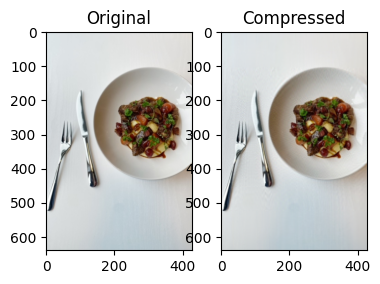

Retained Energy  red 0.9998925190192733
Retained green 0.9998944679411349
Retained Energy blue 0.9998940187870923
0.3044027453271028


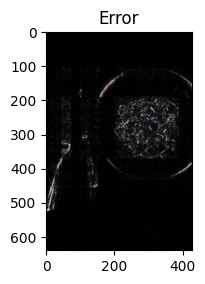

In [4]:
import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt

img = imageio.imread("data/food.jpg")

print(f'Image shape {img.shape}')
cut_off = 350

red = img[:, :, 0]
green = img[:, :, 1]
blue = img[:, :, 2]

U_r, S_r, Vt_r = np.linalg.svd(red, full_matrices=False)
U_g, S_g, Vt_g = np.linalg.svd(green, full_matrices=False)
U_b, S_b, Vt_b = np.linalg.svd(blue, full_matrices=False)

print(f'Original Shape {red.shape}')

U_r_compressed = U_r[:, :U_r.shape[1] - cut_off]# cutting columns
S_r_compressed = S_r[:len(S_r) - cut_off]
Vt_r_compressed = Vt_r[:(Vt_r.shape[0]) - cut_off, :]# cutting rows

U_g_compressed = U_g[:, :U_g.shape[1] - cut_off]# cutting columns
S_g_compressed = S_g[:len(S_g) - cut_off]
Vt_g_compressed = Vt_g[:(Vt_g.shape[0]) - cut_off, :]# cutting rows

U_b_compressed = U_b[:, :U_b.shape[1] - cut_off]# cutting columns
S_b_compressed = S_b[:len(S_b) - cut_off]
Vt_b_compressed = Vt_b[:(Vt_b.shape[0]) - cut_off, :]# cutting rows

#Reconstruct
A_reconstructed_r = U_r_compressed @ np.diag(S_r_compressed) @ Vt_r_compressed

A_reconstructed_g = U_g_compressed @ np.diag(S_g_compressed) @ Vt_g_compressed

A_reconstructed_b = U_b_compressed @ np.diag(S_b_compressed) @ Vt_b_compressed

#Combine
combined = np.stack((A_reconstructed_r, A_reconstructed_g, A_reconstructed_b), axis=2)


#Truncate
combined_round = np.rint(np.clip(combined, 0, 255)).astype(np.uint8)



plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original")

plt.subplot(1, 3, 2)
plt.imshow(combined_round)
plt.title("Compressed")
plt.show()

# energy value

Retained_loss_r = np.linalg.norm(S_r_compressed) / np.linalg.norm(S_r)
Retained_loss_g = np.linalg.norm(S_g_compressed) / np.linalg.norm(S_g)
Retained_loss_b = np.linalg.norm(S_b_compressed) / np.linalg.norm(S_b)

print(f'Retained Energy  red {Retained_loss_r}')
print(f'Retained green {Retained_loss_g}')
print(f'Retained Energy blue {Retained_loss_b}')


#Compression ratio #bytes in compression / # bytes in total
#Total is n*m
# retained 3*k(n+m+1)
#Compression is k(n+m+1)/(n*m)=(428-cutoff)(640+428+1)/(640*428)
def compression_ratio(cut, shape):
    return (shape[1] - cut) * (shape[0] + shape[1] + 1) / (shape[0] * shape[1])


print(compression_ratio(cut_off, red.shape))


# another error evaluation

Error_sq=(combined-img)**2
Error_sq=np.rint(np.clip(Error_sq, 0, 255)).astype(np.uint8)
plt.subplot(1, 3, 3)
plt.imshow(Error_sq)
plt.title("Error")
plt.show()




### Discussion
As can be seen we truncate low singular values by some amount. To compress the image.
Now what is meant by compression

If we save the compressed SVD decomposition instead of the image we have to store

$3k(m+n+1)$ values where the original image was $3(n\times m )$ so the relative compression in terms of data is

$C=\frac{k(m+n+1)}{mn}$

Which in our case is
$C=\frac{k(640+428+1)}{640 \cdot 428}=k0.004$

If $k=8$ $C=0.03$ so we only store $3 \%$ bytes

But then of course you have to reconstruct which takes some computation

So it is kind of a trade of in storage and computation.


The criteria of truncating can of course be experimental, but one criteria could be energy

$$
\text{Energy Retention}=\frac{\sum_{i=1}^{k}\sigma_i^2}{\sum_{i=1}^{\min(n.m)}\sigma_i^2}
$$
where k is the number of singular values kept in the representation

We have in this experiment printed this value, and it can be discussed how good it is for deciding cutoff level